# 01 - OHLCV

Price history for **ETHUSDT**, 1-day candles, sourced from Binance
and stored in `database/market.db`.

This notebook covers:

1. Loading candles into a pandas DataFrame
2. Adding technical indicators (SMA, EMA, RSI, MACD, ATR)
3. Plotting price with moving averages
4. Plotting RSI to spot overbought / oversold zones
5. Summary statistics (return, volatility, drawdown)


## Setup

Import the project's analysis modules and set plotting defaults.

In [1]:
# --- setup --------------------------------------------------------
import sys
sys.path.insert(0, r"D:\Projects\done\eth_bot\eth_bot_v2")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from analysis.loader import load_ohlcv
from analysis.indicators import add_all
from analysis import stats

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 40)
plt.rcParams["figure.figsize"] = (12, 4)

## 1. Load the data

`load_ohlcv()` returns a DataFrame indexed by date with columns
`open`, `high`, `low`, `close`, `volume`.

In [2]:
df = load_ohlcv()
print(f"rows: {len(df)}")
print(f"range: {df.index.min().date()} -> {df.index.max().date()}")
df.tail()

rows: 2189
range: 2020-10-05 -> 2026-10-02


,open,high,low,close,volume
date,,,,,
2026-09-28,2688.65,2721.42,2635.69,2688.71,291823.7819
2026-09-29,2688.71,2748.60,2652.20,2677.98,315936.4377
2026-09-30,2677.98,2738.51,2656.92,2686.01,271934.9508
2026-10-01,2686.01,2722.00,2673.13,2706.42,263392.0729
2026-10-02,2706.43,2777.33,2650.88,2668.59,423663.9677


## 2. Add indicators

`add_all()` appends:

| Column | Meaning |
|---|---|
| `sma_50`, `sma_200` | simple moving averages |
| `ema_12`, `ema_26`  | exponential moving averages |
| `rsi_14`            | relative strength index (0-100) |
| `macd`, `macd_sig`, `macd_hist` | MACD line, signal, histogram |
| `atr_14`            | average true range |

In [3]:
df = add_all(df)
df[["close", "sma_50", "sma_200", "rsi_14", "macd", "atr_14"]].tail(5)

,close,sma_50,sma_200,rsi_14,macd,atr_14
date,,,,,,
2026-09-28,2688.71,2404.2164,2104.92725,64.264507,86.766912,99.002143
2026-09-29,2677.98,2420.3128,2107.85605,78.000000,82.196324,94.379286
2026-09-30,2686.01,2436.3812,2110.80530,77.459849,78.319239,95.812143
2026-10-01,2706.42,2452.9134,2113.44590,77.054623,76.017258,94.290000
2026-10-02,2668.59,2468.5622,2115.02400,58.020972,70.329640,88.385714


## 3. Price and moving averages

Crosses between SMA50 and SMA200 are classic regime signals:
SMA50 above SMA200 = uptrend, below = downtrend.

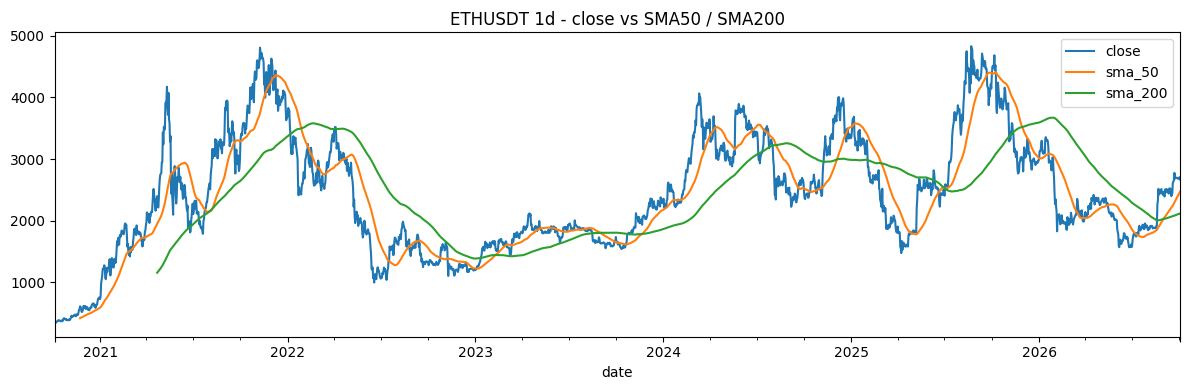

In [4]:
df[["close", "sma_50", "sma_200"]].plot(title="ETHUSDT 1d - close vs SMA50 / SMA200")
plt.tight_layout()
plt.show()

## 4. RSI(14)

- RSI > 70 → traditionally "overbought"
- RSI < 30 → traditionally "oversold"

Not a signal by itself, but useful as a filter combined with trend.

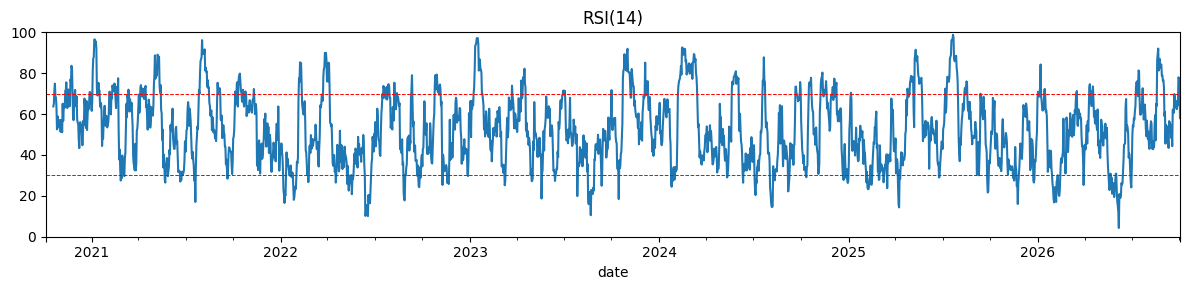

In [5]:
fig, ax = plt.subplots(figsize=(12, 3))
df["rsi_14"].plot(ax=ax, title="RSI(14)")
ax.axhline(70, ls="--", lw=0.7, color="red")
ax.axhline(30, ls="--", lw=0.7, color="green")
ax.set_ylim(0, 100)
plt.tight_layout()
plt.show()

## 5. MACD

- `macd` crosses above `macd_sig` → bullish momentum shift
- `macd` crosses below `macd_sig` → bearish momentum shift
- histogram = `macd - macd_sig`, easier to read at a glance

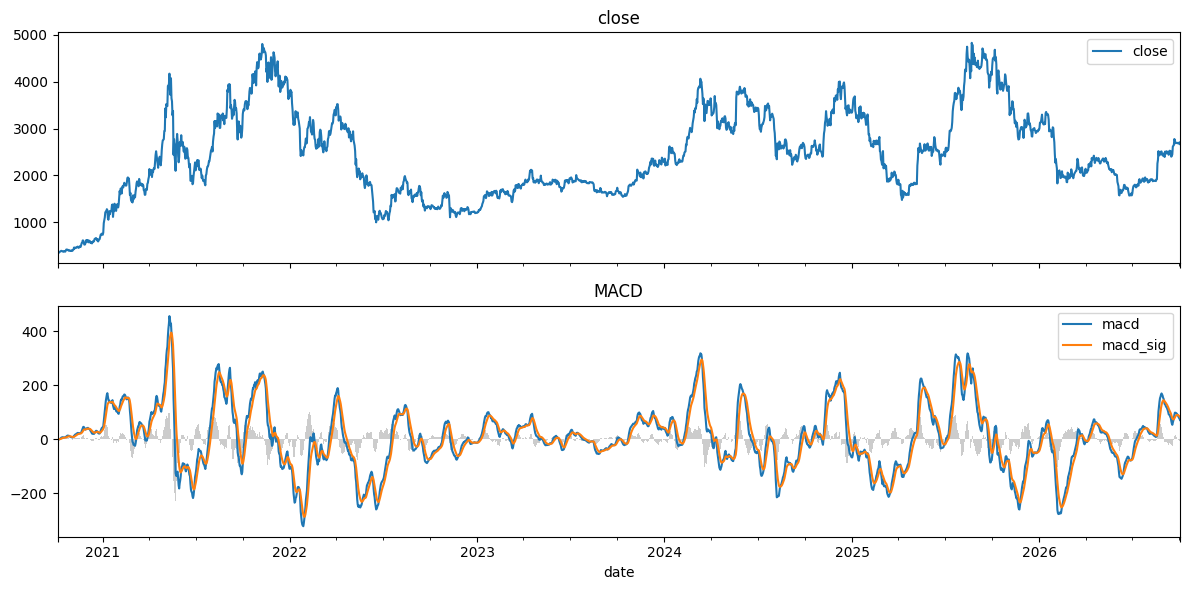

In [6]:
fig, (a1, a2) = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
df[["close"]].plot(ax=a1, title="close")
df[["macd", "macd_sig"]].plot(ax=a2)
a2.bar(df.index, df["macd_hist"], width=1.0, alpha=0.4, color="gray")
a2.set_title("MACD")
plt.tight_layout()
plt.show()

## 6. Summary statistics

`stats.summary()` computes:

- total return over the period
- annualized volatility
- Sharpe ratio (0% risk-free)
- maximum drawdown
- best and worst single day

In [7]:
s = stats.summary(df.close)
for k, v in s.items():
    print(f"  {k:<14} {v}")

  start          2020-10-05
  end            2026-10-02
  days           2189
  total_return   6.546490583111775
  ann_vol        0.7712168798133651
  sharpe         0.8220824921243687
  max_drawdown   -0.7930253453633338
  best_day       0.2633288653351713
  worst_day      -0.27737202487652113


## 7. Latest values

A snapshot of the most recent fully-closed daily candle.

In [8]:
last = df.iloc[-1]
print(f"date      : {df.index[-1].date()}")
print(f"close     : {last.close:.2f}")
print(f"sma_50    : {last.sma_50:.2f}")
print(f"sma_200   : {last.sma_200:.2f}")
print(f"rsi_14    : {last.rsi_14:.2f}")
print(f"atr_14    : {last.atr_14:.2f}")
print(f"macd_hist : {last.macd_hist:.4f}")

date      : 2026-10-02
close     : 2668.59
sma_50    : 2468.56
sma_200   : 2115.02
rsi_14    : 58.02
atr_14    : 88.39
macd_hist : -10.7751


## Next steps

- **Gap check** — see `03_data_quality.ipynb` to verify no missing days
- **Returns & vol** — see `02_returns_vol.ipynb`
- **Cross-source** — join with funding rate and open interest in `04_funding_oi.ipynb`
- **Daily report** — the same stats are written automatically by
  `python -m analysis.reports` into `reports/daily/YYYY-MM-DD/summary.md`
